# Práctica 5 - Análisis Exploratorio de Datos (EDA)

**Sesión 5 - Exploración de datos**    
**Herramientas:** Python, pandas y Matplotlib  
**Dataset:** `clientes_ecommerce.csv`

## Objetivos

En esta práctica aprenderás a:

- realizar un análisis exploratorio de un dataset
- estudiar distribuciones numéricas y categóricas
- interpretar media, mediana, cuartiles y desviación estándar
- utilizar histogramas, gráficos de barras, boxplots y diagramas de dispersión
- detectar posibles valores atípicos mediante el IQR
- estudiar relaciones entre variables
- calcular e interpretar correlaciones
- comparar grupos mediante `groupby()` y `crosstab()`
- diferenciar asociación y causalidad
- comunicar hallazgos respaldados por evidencia

> **Importante:** no basta con generar resultados o gráficos. Cada análisis debe ir acompañado de una **interpretación**

## Preparación

Coloca `clientes_ecommerce.csv` en la misma carpeta que este notebook.

Importa NumPy, pandas y Matplotlib y carga el dataset en un DataFrame llamado `df`

In [1]:
# TODO: importa numpy, pandas y matplotlib.pyplot
import numpy as np #trabajar con arrays y operaciones con numeros
import matplotlib.pyplot as plt #trabajar con objeto DataFrame especifico de pandas usado para manipular tablas
import pandas as pd #libreria para hacer graficos de visualizacion representacion grafica de los datos

# TODO: carga clientes_ecommerce.csv en un DataFrame llamado df
df = pd.read_csv('clientes_ecommerce.csv')
# TODO: muestra las primeras filas
df.head(20) 

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


# Parte 1 - Inspección inicial

## Ejercicio 1

Realiza una inspección inicial:

1. Muestra las primeras 10 filas.
2. Consulta las dimensiones.
3. Muestra los nombres de las columnas.
4. Consulta los tipos de datos.
5. Utiliza `info()`.

In [2]:
# TODO: muestra las primeras 10 filas
df.head(10) 

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


In [3]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

In [4]:
# TODO: muestra los nombres de las columnas
for c in df.columns:
    print(c)

cliente_id
edad
antiguedad_meses
ingresos_anuales
gasto_mensual
num_compras
devoluciones
dispositivo
zona
nivel_fidelidad
satisfaccion
compra_proximo_mes


In [5]:
# TODO: consulta los tipos de datos dtypes devuelve un objeto que tiene clave que es el nombre de la columna y valor asociado a la clave es el tipo
df.dtypes

for columna, tipo in df.dtypes.items():
        print(f" {columna}: {tipo}")

 cliente_id: int64
 edad: int64
 antiguedad_meses: float64
 ingresos_anuales: float64
 gasto_mensual: float64
 num_compras: int64
 devoluciones: int64
 dispositivo: str
 zona: str
 nivel_fidelidad: str
 satisfaccion: int64
 compra_proximo_mes: str


In [6]:
# TODO: utiliza info()
df.info()  

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Responde

1. ¿Cuántas muestras contiene?
2. ¿Cuántas columnas?
3. ¿Cuál es la unidad de observación?
4. ¿Cuál es el identificador?
5. ¿Cuál es el target?
6. ¿Qué columnas tienen valores ausentes?

**Respuesta:**  
1\. 400  
2\. 12  
3\. El cliente  
4\. cliente_id  
5\. compra_proximo_mes  
6\. antiguedad_meses, ingresos_anuales y gasto_mensual

# Parte 2 - Exploración de una variable numérica

Vamos a estudiar `gasto_mensual`.

## Ejercicio 2 - Estadística descriptiva

Obtén el número de valores, media, mediana, desviación estándar, mínimo, \(Q_1\), \(Q_2\), \(Q_3\) y máximo.

In [7]:
# TODO: muestra describe() para gasto_mensual
print(df['gasto_mensual'].describe())
print("Mediana :",df['gasto_mensual'].median())
print ("Q1: ", df['gasto_mensual'].quantile(.25)) #el 25% de las muestras estan por debajo de 39
print ("Q2: ", df['gasto_mensual'].quantile(.5)) #el 50% de las muestras estan por debajo de de 61
print ("Q3: ", df['gasto_mensual'].quantile(.75)) # el 75% x debajo de 90

# TODO: calcula las medidas necesarias

count    397.000000
mean      69.089320
std       39.023238
min        5.770000
25%       39.720000
50%       61.170000
75%       90.150000
max      260.000000
Name: gasto_mensual, dtype: float64
Mediana : 61.17
Q1:  39.72
Q2:  61.17
Q3:  90.15


### Completa

| Medida | Valor |
|---|---:|
| Número de valores | 397 |
| Media | 69,09 |
| Mediana | 61,17 |
| Desviación estándar | 39,02 |
| Mínimo | 5,77 |
| Q1 | 39,72 |
| Q2 | 61,17 |
| Q3 | 90,15 |
| Máximo | 260,00 |

### Interpreta

1. ¿Coinciden exactamente media y mediana?
2. ¿Cuál es mayor?
3. ¿Qué puede indicar esta diferencia sobre la distribución?
4. ¿Entre qué valores se encuentra aproximadamente el 50 % central?

**Respuesta:**  
1\. No  
2\. La media (69,09) es mayor que la mediana (61,17)  
3\. Que hay algunos clientes que gastan mucho y suben la media, la distribucion tiene cola a la derecha  
4\. Entre 39,72 y 90,15 €

# Parte 3 - Visualizar la distribución

## Ejercicio 3 - Histograma

Crea un histograma de `gasto_mensual` utilizando aproximadamente `bins=15`.

Añade título y etiquetas en ambos ejes.

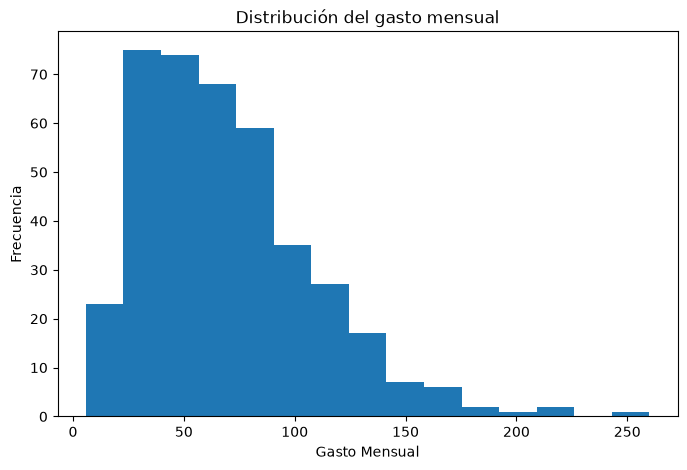

In [8]:
# TODO: crea el histograma de gasto_mensual
plt.figure(figsize=(8,5))
plt.hist(df['gasto_mensual'].dropna(), bins=15)  # asimetría positiva: sesgada a la derecha
plt.xlabel("Gasto Mensual")
plt.ylabel("Frecuencia")
plt.title("Distribución del gasto mensual")
plt.show()

### Interpreta

1. ¿Dónde parece concentrarse la mayoría de los clientes?
2. ¿La distribución parece aproximadamente simétrica?
3. ¿Existe una cola hacia valores altos o bajos?
4. ¿Observas valores alejados del resto?

**Respuesta:**  
1\. Entre 20 y 100 €, sobre todo entre 40 y 60 €  
2\. No  
3\. Si, hacia valores altos  
4\. Si, algunos por encima de 160 €, el maximo es 260 €

# Parte 4 - Boxplot y valores atípicos

## Ejercicio 4

Representa `gasto_mensual` mediante un boxplot. Trata adecuadamente los valores ausentes.

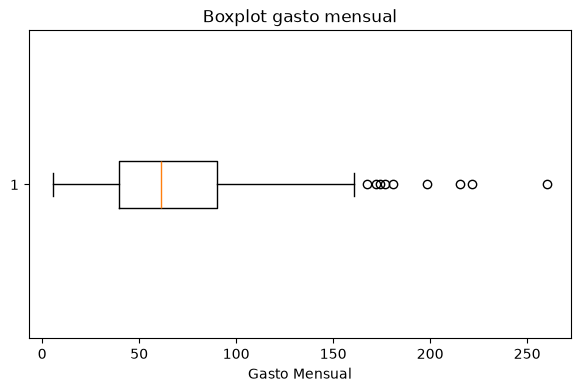

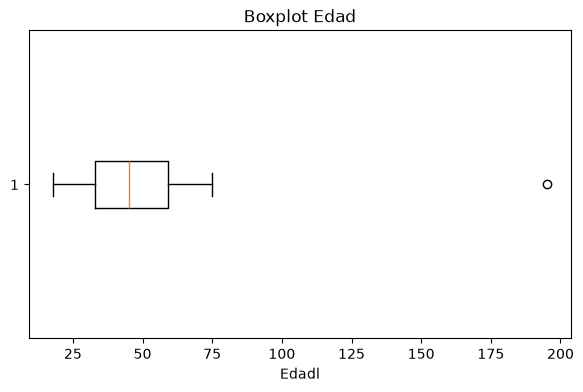

In [9]:
# TODO: crea un boxplot de gasto_mensual permite buscar valores atipicos
plt.figure(figsize=(7,4))
plt.boxplot(df['gasto_mensual'].dropna(), orientation='horizontal')
plt.xlabel("Gasto Mensual")
plt.title("Boxplot gasto mensual")
plt.show()

plt.figure(figsize=(7,4))
plt.boxplot(df['edad'].dropna(), orientation='horizontal')
plt.xlabel("Edadl")
plt.title("Boxplot Edad")
plt.show()

### Interpreta

1. ¿Dónde se encuentra aproximadamente la mediana?
2. ¿Observas posibles outliers?
3. ¿Aparecen principalmente por encima o por debajo?
4. ¿Podemos afirmar que esos valores son errores únicamente observando el boxplot? Justifica.

**Respuesta:**  
1\. Sobre 61 €  
2\. Si  
3\. Por encima  
4\. No, solo sabemos que son valores raros, pueden ser clientes que gastan mucho de verdad

# Parte 5 - Detectar outliers mediante IQR

## Ejercicio 5

Calcula:

$$
IQR=Q_3-Q_1
$$

y:

$$
L_{inferior}=Q_1-1.5IQR
$$

$$
L_{superior}=Q_3+1.5IQR
$$

Después localiza los clientes cuyo `gasto_mensual` esté fuera de estos límites y guarda el resultado en `outliers_gasto`.

In [10]:
# TODO: calcula Q1, Q3 e IQR outlier valores atipicos que pueden o no ser errrores

Q1=df['gasto_mensual'].quantile(.25) #el 25% de las muestras estan por debajo de 39
Q2=df['gasto_mensual'].quantile(.5) #el 50% de las muestras estan por debajo de de 61
Q3=df['gasto_mensual'].quantile(.75)

#rango intercuantilico
IQR = Q3 - Q1
# TODO: calcula los límites inferior y superior
limite_inferior = Q1 -1.5*IQR
limite_superior = Q3 + 1.5*IQR

# TODO: muestra los resultados
print(f"IQR : {IQR:.2f}, Limite inferior: {limite_inferior:.2f}, Limite superior:{limite_superior:.2f}")

Q1=df['edad'].quantile(.25) #el 25% de las muestras estan por debajo de 39
Q2=df['edad'].quantile(.5) #el 50% de las muestras estan por debajo de de 61
Q3=df['edad'].quantile(.75)

#rango intercuantilico
IQR = Q3 - Q1
# TODO: calcula los límites inferior y superior
limite_inferior1 = Q1 -1.5*IQR
limite_superior2 = Q3 + 1.5*IQR

# TODO: muestra los resultados
print(f"IQR : {IQR:.2f}, Limite inferior: {limite_inferior1:.2f}, Limite superior:{limite_superior2:.2f}")

IQR : 50.43, Limite inferior: -35.93, Limite superior:165.80
IQR : 26.00, Limite inferior: -6.00, Limite superior:98.00


In [11]:
# TODO: crea outliers_gastos
filtro = (df['gasto_mensual'] < limite_inferior) | (df['gasto_mensual'] > limite_superior)
outliers_gastos = df[filtro]


# TODO: muestra los posibles outliers
print(outliers_gastos)

filtro2 = (df['edad'] < limite_inferior1) | (df['edad'] > limite_superior2)
outliers_edad = df[filtro2]

# TODO: muestra los posibles outliers
outliers_edad

     cliente_id  edad  antiguedad_meses  ingresos_anuales  gasto_mensual  \
50        20051    75              49.0          22908.36         176.52   
68        20069    29              78.0          33382.86         215.30   
202       20203    45              57.0          24727.71         167.26   
203       20204    25              41.0          39329.38         173.91   
207       20208    41              65.0          25812.18         221.59   
268       20269    21              61.0          34737.20         198.28   
292       20293    20              94.0          31714.55         172.31   
318       20319    56              38.0           9000.00         180.60   
398       20399    75              85.0          40391.73         260.00   

     num_compras  devoluciones dispositivo    zona nivel_fidelidad  \
50             3             1       Móvil    Este             Oro   
68             8             2       Móvil  Centro          Bronce   
202            7             

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
137,20138,195,106.0,32593.41,138.99,6,0,Móvil,Este,Plata,3,No


In [12]:
# outliers_gasto, como pide el enunciado
outliers_gasto = outliers_gastos
print("Nº posibles outliers:", len(outliers_gasto))
print("Porcentaje sobre 400 clientes:", round(len(outliers_gasto) / len(df) * 100, 2), "%")
print("Mayor gasto_mensual:", df["gasto_mensual"].max())
outliers_gasto[["cliente_id", "gasto_mensual"]].sort_values("gasto_mensual")

Nº posibles outliers: 9
Porcentaje sobre 400 clientes: 2.25 %
Mayor gasto_mensual: 260.0


,cliente_id,gasto_mensual
202,20203,167.26
292,20293,172.31
203,20204,173.91
50,20051,176.52
318,20319,180.60
268,20269,198.28
68,20069,215.30
207,20208,221.59
398,20399,260.00


### Responde

1. ¿Cuántos posibles outliers has encontrado?
2. ¿Qué porcentaje representan?
3. ¿Cuál es el mayor `gasto_mensual`?
4. ¿Eliminarías automáticamente estas observaciones?
5. ¿Qué investigarías antes?

**Respuesta:**  
1\. 9  
2\. Un 2,25 %  
3\. 260 €  
4\. No  
5\. Si el dato es correcto, mirando sus compras, ingresos y nivel de fidelidad

# Parte 6 - Comparar varias distribuciones

## Ejercicio 6

Analiza:

- `edad`
- `ingresos_anuales`
- `gasto_mensual`
- `num_compras`
- `devoluciones`

Consulta sus estadísticas descriptivas y crea un histograma independiente para cada variable.

In [13]:
# TODO: consulta las estadísticas descriptivas de las variables indicadas
variables = ["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]
df[variables].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
edad,400.0,46.40,18.01,18.00,33.00,45.00,59.00,195.00
ingresos_anuales,396.0,36440.92,14325.23,9000.00,26034.09,36817.27,45969.03,82925.37
gasto_mensual,397.0,69.09,39.02,5.77,39.72,61.17,90.15,260.00
num_compras,400.0,8.22,2.78,2.00,6.00,8.00,10.00,17.00
devoluciones,400.0,1.23,1.14,0.00,0.00,1.00,2.00,5.00


In [14]:
# TODO: calcula sus medianas
df[variables].median()

edad                   45.000
ingresos_anuales    36817.275
gasto_mensual          61.170
num_compras             8.000
devoluciones            1.000
dtype: float64

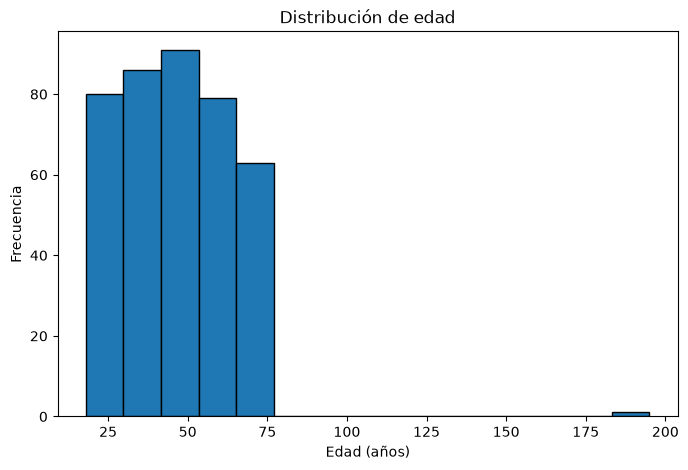

In [15]:
# TODO: histograma de edad
plt.figure(figsize=(8,5))
plt.hist(df["edad"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de edad")
plt.xlabel("Edad (años)")
plt.ylabel("Frecuencia")
plt.show()

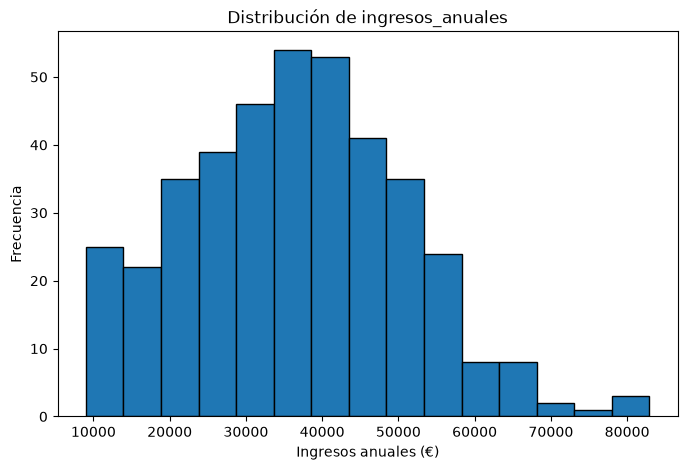

In [16]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8,5))
plt.hist(df["ingresos_anuales"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de ingresos_anuales")
plt.xlabel("Ingresos anuales (€)")
plt.ylabel("Frecuencia")
plt.show()

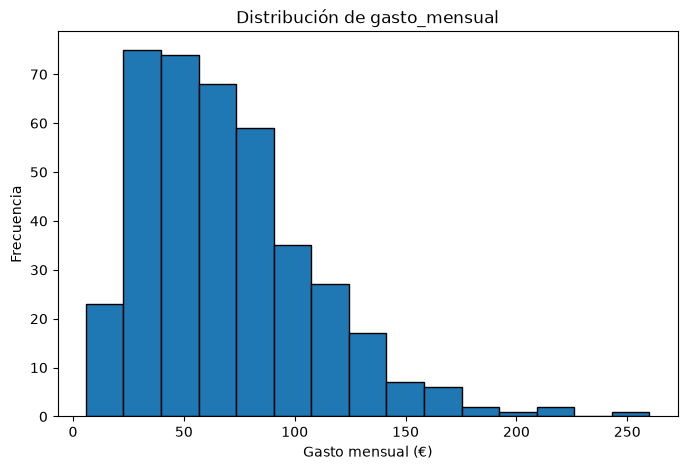

In [17]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8,5))
plt.hist(df["gasto_mensual"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de gasto_mensual")
plt.xlabel("Gasto mensual (€)")
plt.ylabel("Frecuencia")
plt.show()

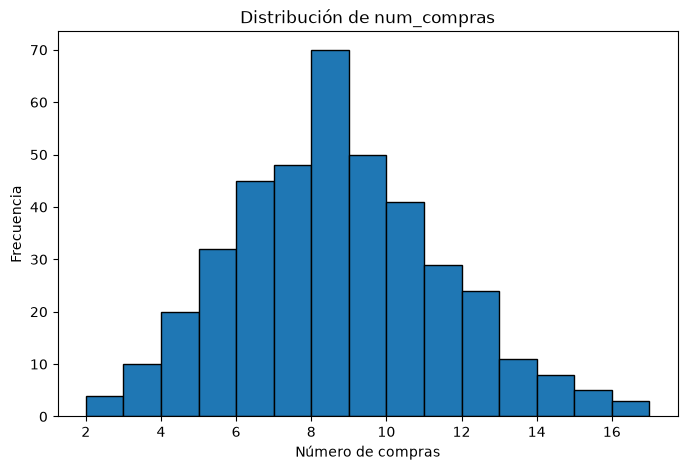

In [18]:
# TODO: histograma de num_compras
plt.figure(figsize=(8,5))
plt.hist(df["num_compras"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de num_compras")
plt.xlabel("Número de compras")
plt.ylabel("Frecuencia")
plt.show()

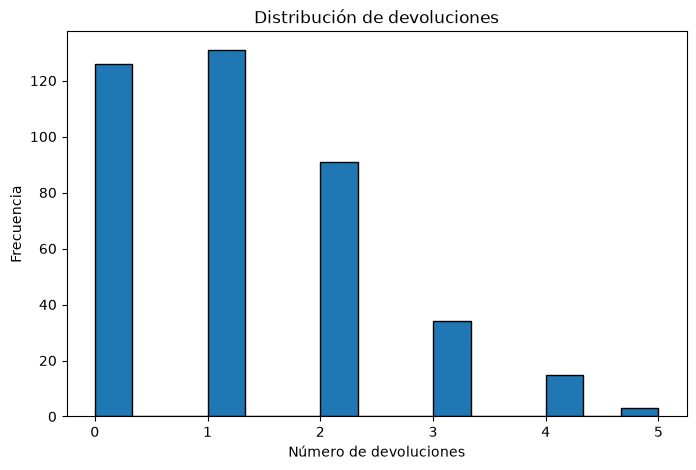

In [19]:
# TODO: histograma de devoluciones
plt.figure(figsize=(8,5))
plt.hist(df["devoluciones"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de devoluciones")
plt.xlabel("Número de devoluciones")
plt.ylabel("Frecuencia")
plt.show()

### Completa

| Variable | Media | Mediana | Mínimo | Máximo | Observación relevante |
|---|---:|---:|---:|---:|---|
| edad | 46,40 | 45,00 | 18 | 195 | Hay una edad de 195, imposible |
| ingresos_anuales | 36.440,92 | 36.817,27 | 9.000,00 | 82.925,37 | Bastante simetrica |
| gasto_mensual | 69,09 | 61,17 | 5,77 | 260,00 | Cola a la derecha |
| num_compras | 8,22 | 8,00 | 2 | 17 | Simetrica |
| devoluciones | 1,23 | 1,00 | 0 | 5 | Casi todos entre 0 y 2 |

### Busca una observación sospechosa

- ¿Qué variable es?
- ¿Qué valor tiene?
- ¿Por qué parece sospechoso?
- ¿Es un outlier?
- ¿Podemos afirmar directamente que es un error?
- ¿Qué harías antes de modificarlo?

**Respuesta:**  
Variable: edad  
Valor: 195 años  
Es imposible, el resto de edades esta entre 18 y 75  
Si, es un outlier  
Casi seguro que es un error pero no sabemos el valor correcto  
Comprobaria el dato original y si no se puede lo pondria como NaN

# Parte 7 - Variables categóricas

## Ejercicio 7 - Frecuencias

Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes`.

Calcula frecuencias absolutas, relativas y porcentajes mediante `value_counts()`.

In [20]:
# TODO: analiza dispositivo
print(df['dispositivo'].value_counts())                    # absolutas
print(df['dispositivo'].value_counts(normalize=True))      # relativas
print(df['dispositivo'].value_counts(normalize=True) * 100)  # porcentajes

print(df['zona'].value_counts())                    # absolutas
print(df['zona'].value_counts(normalize=True))      # relativas
print(df['zona'].value_counts(normalize=True) * 100)  # porcentajes

print(df['nivel_fidelidad'].value_counts())                    # absolutas
print(df['nivel_fidelidad'].value_counts(normalize=True))      # relativas
print(df['nivel_fidelidad'].value_counts(normalize=True) * 100)  # porcentajes

print(df['compra_proximo_mes'].value_counts())                    # absolutas
print(df['compra_proximo_mes'].value_counts(normalize=True))      # relativas
print(df['compra_proximo_mes'].value_counts(normalize=True) * 100)  # porcentajes

dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64
dispositivo
Móvil        0.6050
Ordenador    0.3325
Tablet       0.0625
Name: proportion, dtype: float64
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64
zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64
zona
Este      0.2225
Sur       0.2000
Norte     0.1975
Oeste     0.1900
Centro    0.1900
Name: proportion, dtype: float64
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64
nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64
nivel_fidelidad
Bronce     0.4050
Plata      0.2625
Oro        0.2075
Platino    0.1250
Name: proportion, dtype: float64
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64
compra_proximo_mes
No    24

In [21]:
# TODO: analiza zona
pd.DataFrame({
    "absoluta": df["zona"].value_counts(),
    "relativa": df["zona"].value_counts(normalize=True).round(4),
    "porcentaje": (df["zona"].value_counts(normalize=True) * 100).round(2)
})

,absoluta,relativa,porcentaje
zona,,,
Este,89,0.2225,22.25
Sur,80,0.2000,20.00
Norte,79,0.1975,19.75
Oeste,76,0.1900,19.00
Centro,76,0.1900,19.00


In [22]:
# TODO: analiza nivel_fidelidad
pd.DataFrame({
    "absoluta": df["nivel_fidelidad"].value_counts(),
    "relativa": df["nivel_fidelidad"].value_counts(normalize=True).round(4),
    "porcentaje": (df["nivel_fidelidad"].value_counts(normalize=True) * 100).round(2)
})

,absoluta,relativa,porcentaje
nivel_fidelidad,,,
Bronce,162,0.4050,40.50
Plata,105,0.2625,26.25
Oro,83,0.2075,20.75
Platino,50,0.1250,12.50


In [23]:
# TODO: analiza compra_proximo_mes
pd.DataFrame({
    "absoluta": df["compra_proximo_mes"].value_counts(),
    "relativa": df["compra_proximo_mes"].value_counts(normalize=True).round(4),
    "porcentaje": (df["compra_proximo_mes"].value_counts(normalize=True) * 100).round(2)
})

,absoluta,relativa,porcentaje
compra_proximo_mes,,,
No,246,0.615,61.5
Sí,154,0.385,38.5


### Completa

| Variable | Categoría más frecuente | Nº muestras | Porcentaje |
|---|---|---:|---:|
| dispositivo | Movil | 242 | 60,50 % |
| zona | Este | 89 | 22,25 % |
| nivel_fidelidad | Bronce | 162 | 40,50 % |
| compra_proximo_mes | No | 246 | 61,50 % |

# Parte 8 - Visualización de variables categóricas

## Ejercicio 8

Crea gráficos de barras independientes para:

- `dispositivo`
- `nivel_fidelidad`
- `compra_proximo_mes`

Todos deben incluir título y etiquetas.

Index(['Móvil', 'Ordenador', 'Tablet'], dtype='str', name='dispositivo')
[242 133  25]


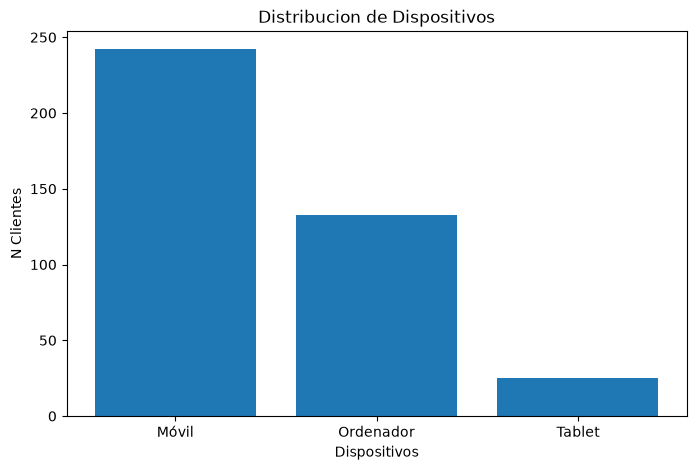

In [24]:
# TODO: gráfico de barras de dispositivo
conteos_disp = df['dispositivo'].value_counts()
print(conteos_disp.index)
print(conteos_disp.values)


plt.figure(figsize=(8,5))
plt.bar(conteos_disp.index, conteos_disp.values)
plt.xlabel("Dispositivos")
plt.ylabel("N Clientes")
plt.title("Distribucion de Dispositivos")
plt.show()

Index(['Bronce', 'Plata', 'Oro', 'Platino'], dtype='str', name='nivel_fidelidad')
[162 105  83  50]


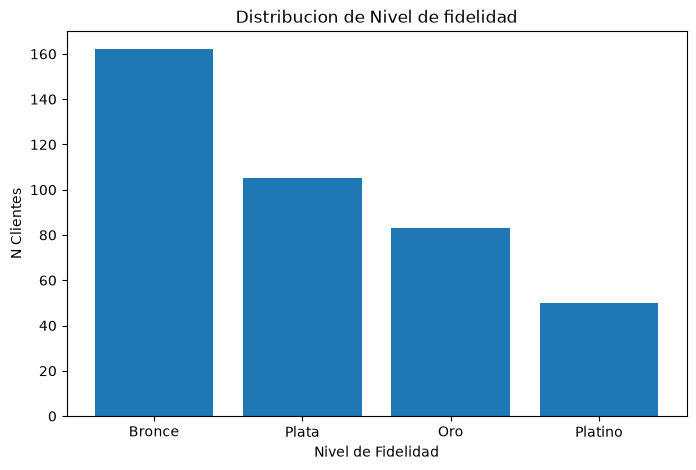

In [25]:
# TODO: gráfico de barras de nivel_fidelidad
conteos_fide = df['nivel_fidelidad'].value_counts()
print(conteos_fide.index)
print(conteos_fide.values)


plt.figure(figsize=(8,5))
plt.bar(conteos_fide.index, conteos_fide.values)
plt.xlabel("Nivel de Fidelidad")
plt.ylabel("N Clientes")
plt.title("Distribucion de Nivel de fidelidad")
plt.show()

Index(['No', 'Sí'], dtype='str', name='compra_proximo_mes')
[246 154]


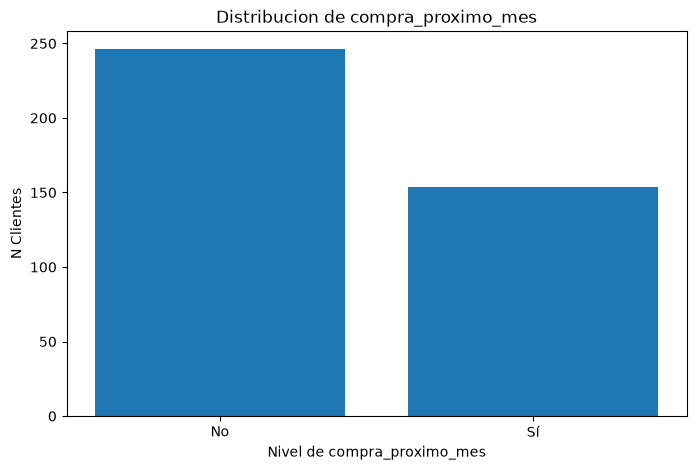

In [26]:
# TODO: gráfico de barras de compra_proximo_mes
conteos_fide = df['compra_proximo_mes'].value_counts()
print(conteos_fide.index)
print(conteos_fide.values)


plt.figure(figsize=(8,5))
plt.bar(conteos_fide.index, conteos_fide.values)
plt.xlabel("Nivel de compra_proximo_mes")
plt.ylabel("N Clientes")
plt.title("Distribucion de compra_proximo_mes")
plt.show()

### Interpreta

Escribe al menos una conclusión sobre cada gráfico.

Para `compra_proximo_mes`, responde además:

> ¿Las clases están perfectamente equilibradas?

Justifica utilizando porcentajes.

**Respuesta:**  
Dispositivo: la mayoria usa el movil (60,5 %) y muy pocos la tablet (6,25 %)  
Nivel de fidelidad: cuanto mas alto el nivel menos clientes, Bronce es el que mas tiene (40,5 %)  
compra_proximo_mes: hay mas No que Si  
No estan equilibradas, 61,5 % No y 38,5 % Si

# Parte 9 - Relación entre dos variables numéricas

Queremos investigar:

> **¿Existe alguna relación entre el número de compras realizadas y el gasto mensual?**

## Ejercicio 9 - Scatter plot

Representa:

$$
X=\text{num\_compras}
$$

$$
Y=\text{gasto\_mensual}
$$

mediante un diagrama de dispersión.

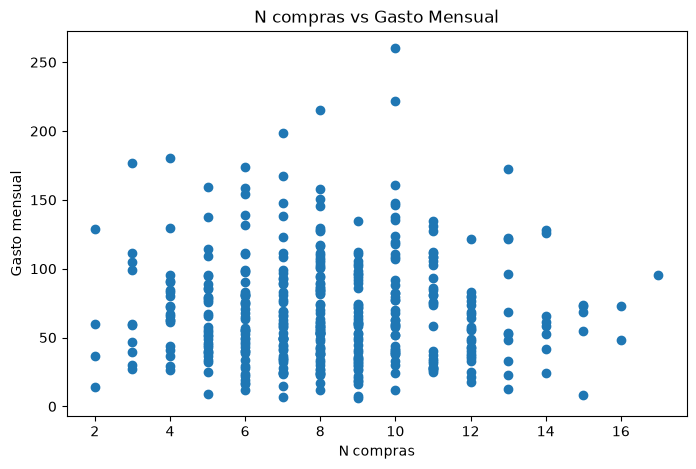

In [27]:
# TODO: crea un scatter plot de num_compras frente a gasto_mensual
plt.figure(figsize=(8,5))
plt.scatter(df['num_compras'], df['gasto_mensual'])
plt.xlabel("N compras")
plt.ylabel("Gasto mensual")
plt.title("N compras vs Gasto Mensual")
plt.show()

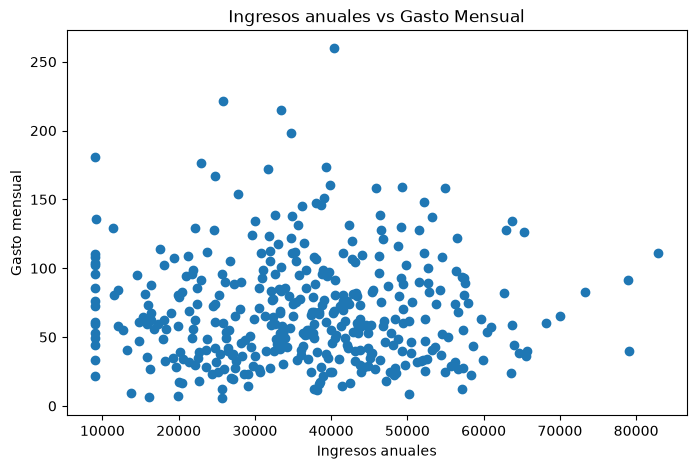

In [28]:
plt.figure(figsize=(8,5))
plt.scatter(df['ingresos_anuales'], df['gasto_mensual'])
plt.xlabel("Ingresos anuales")
plt.ylabel("Gasto mensual")
plt.title("Ingresos anuales vs Gasto Mensual")
plt.show()

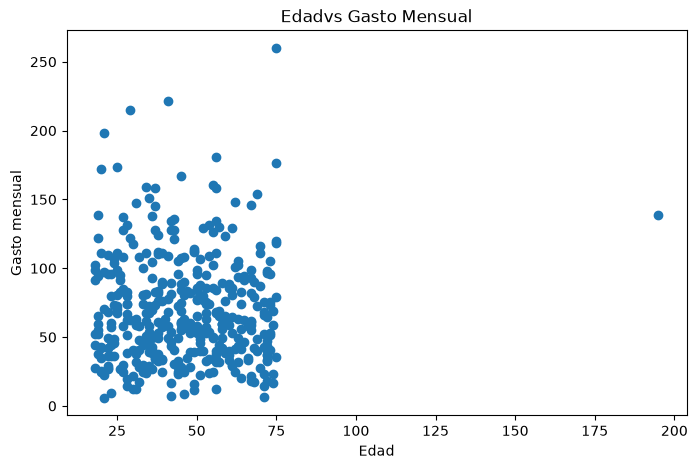

In [29]:
plt.figure(figsize=(8,5))
plt.scatter(df['edad'], df['gasto_mensual'])
plt.xlabel("Edad")
plt.ylabel("Gasto mensual")
plt.title("Edadvs Gasto Mensual")
plt.show()

### Antes de calcular la correlación

1. ¿Parece existir una relación?
2. ¿Parece positiva o negativa?
3. ¿Parece fuerte o débil?
4. ¿Observas muestras especialmente alejadas?

**Respuesta:**  
1\. No parece haber relacion  
2\. Ni positiva ni negativa  
3\. Muy debil o nula  
4\. Si, algunos clientes con gasto muy alto

# Parte 10 - Correlación

## Ejercicio 10

Calcula la correlación entre `num_compras` y `gasto_mensual` utilizando `corr()`.

In [30]:
# TODO: calcula la correlación entre num_compras y gasto_mensual
print(df['num_compras'].corr(df['gasto_mensual']))

-0.014165499001183275


### Interpreta

1. ¿Cuál es el valor de \(r\)?
2. ¿Es positivo o negativo?
3. ¿Qué significa el signo?
4. ¿Coincide con lo observado en el scatter plot?
5. ¿Podemos afirmar que realizar más compras **provoca** un mayor gasto mensual? Justifica.

**Respuesta:**  
1\. r = -0,014  
2\. Negativo pero casi 0  
3\. Si fuera negativo de verdad, cuando una sube la otra baja. Aqui no hay relacion.  
4\. Si, en el scatter tampoco se veia relacion  
5\. No, no hay correlacion y aunque la hubiera no demuestra causalidad

# Parte 11 - Matriz de correlaciones

## Ejercicio 11

Selecciona las variables numéricas y calcula su matriz de correlaciones.

> **Atención:** `cliente_id` es técnicamente numérico, pero conceptualmente es un identificador. No debes incluirlo.

In [31]:
# TODO: selecciona las variables numéricas excluyendo cliente_id
numericas = df.select_dtypes(include='number').drop(columns='cliente_id')

# TODO: calcula y muestra la matriz de correlaciones
correlaciones = numericas.corr()
correlaciones

,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,satisfaccion
edad,1.000000,0.031192,-0.036610,0.021361,-0.077583,-0.097102,-0.062801
antiguedad_meses,0.031192,1.000000,-0.058738,0.006482,-0.099965,-0.056458,-0.040051
ingresos_anuales,-0.036610,-0.058738,1.000000,-0.000367,0.072991,0.000260,-0.062595
gasto_mensual,0.021361,0.006482,-0.000367,1.000000,-0.014165,0.030674,-0.054523
num_compras,-0.077583,-0.099965,0.072991,-0.014165,1.000000,-0.005747,0.092211
devoluciones,-0.097102,-0.056458,0.000260,0.030674,-0.005747,1.000000,0.030817
satisfaccion,-0.062801,-0.040051,-0.062595,-0.054523,0.092211,0.030817,1.000000


### Interpreta

1. ¿Por qué todos los valores de la diagonal son 1?
2. ¿Por qué la matriz es simétrica? la misma cantidad de elementis esta en las columnas
3. Sin considerar la diagonal, ¿qué pareja presenta la correlación positiva más alta? numero de compras y satisfacion llefa casi a 1 pero sigue siendo 0
4. ¿Qué pareja presenta la correlación más negativa?
5. ¿Hay variables cuya correlación sea prácticamente cero?

**Respuesta:**  
1\. Porque es la correlacion de cada variable consigo misma  
2\. Porque la correlacion entre A y B es la misma que entre B y A  
3\. num_compras y satisfaccion, 0,09, muy debil  
4\. antiguedad_meses y num_compras, -0,10  
5\. Si, casi todas, por ejemplo ingresos_anuales y gasto_mensual (0,00)

# Parte 12 - Visualizar las correlaciones

## Ejercicio 12

Representa la matriz mediante `plt.imshow()`.

Añade nombres de variables en ambos ejes, barra de color y título.

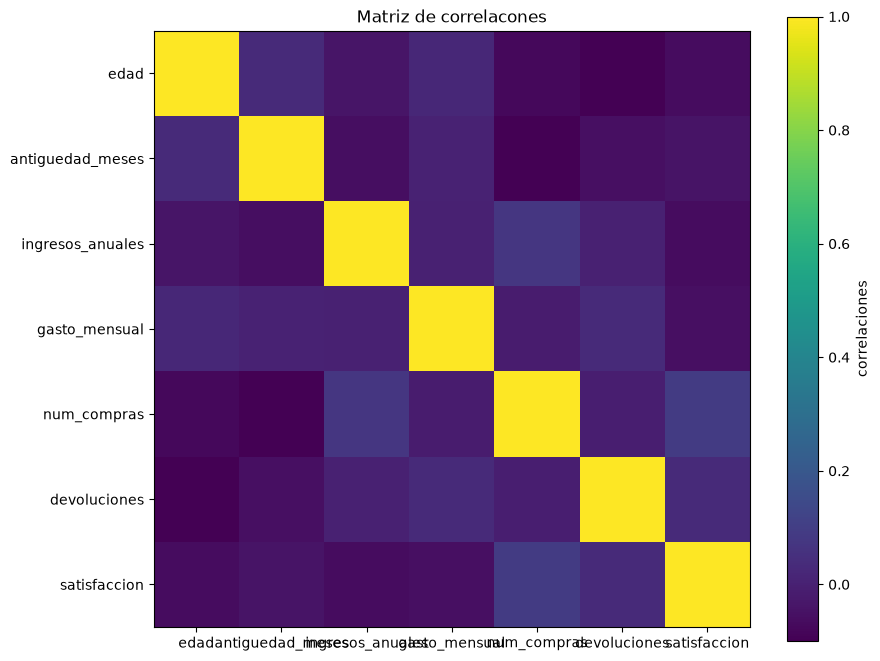

In [32]:
# TODO: representa la matriz de correlaciones con plt.imshow()
# TODO: representa la matriz de correlaciones con plt.imshow()
plt.figure(figsize=(9,7))
plt.imshow(correlaciones)
plt.xticks(range(len(correlaciones.columns)))
#eje x
plt.xticks(
    range(len(correlaciones.columns)),
    correlaciones.columns
)
#eje y
plt.yticks(
    range(len(correlaciones.columns)),
    correlaciones.columns
)
#barra de color lateral
plt.colorbar(label="correlaciones")

plt.title("Matriz de correlacones")

plt.tight_layout()
plt.show()

### Interpreta tres relaciones

Selecciona tres relaciones de la matriz y explica qué significa cada valor.

1. num_compras y satisfaccion (0,09): casi no hay relacion, los mas satisfechos compran apenas un poco mas
2. antiguedad_meses y num_compras (-0,10): relacion muy debil, los mas antiguos no compran mas
3. ingresos_anuales y gasto_mensual (0,00): no hay relacion, ganar mas no hace gastar mas aqui

Recuerda:

$$
\boxed{\text{correlación}\neq\text{causalidad}}
$$

# Parte 13 - Variable numérica frente a categórica

Queremos investigar:

> **¿Los clientes que realizan una compra el mes siguiente presentan un gasto histórico diferente?**

## Ejercicio 13

Utiliza `groupby()` para obtener para cada valor de `compra_proximo_mes`:

- número de clientes
- gasto medio
- mediana
- desviación estándar.

In [33]:
df.groupby('nivel_fidelidad')['gasto_mensual'].agg( #nicel de fidelidad se pone primero porque es la categorica
    numero_clientes="count",
    gasto_medio="mean",
    mediana="median",
    desviacion_estandar="std"
)

,numero_clientes,gasto_medio,mediana,desviacion_estandar
nivel_fidelidad,,,,
Bronce,159,68.201321,57.79,42.580449
Oro,83,70.932410,63.31,37.513417
Plata,105,68.686095,62.79,37.078855
Platino,50,69.700400,68.06,34.328374


In [34]:
df.groupby('nivel_fidelidad')['ingresos_anuales'].agg( #nicel de fidelidad se pone primero porque es la categorica
    numero_clientes="count",
    ingresos_medios="mean",
    mediana="median",
    desviacion_estandar="std"
) #varia 159 y 162 por el NAN

,numero_clientes,ingresos_medios,mediana,desviacion_estandar
nivel_fidelidad,,,,
Bronce,162,36409.247963,37028.050,13261.941850
Oro,83,35921.890843,36831.090,14873.491333
Plata,103,37097.991068,37994.140,14716.674654
Platino,48,36035.339167,34151.525,16266.443749


In [35]:
df.groupby('compra_proximo_mes')['ingresos_anuales'].agg(
    numero_clientes="count",
    ingresos_medios="mean",
    mediana="median",
    desviacion_estandar="std"
)

,numero_clientes,ingresos_medios,mediana,desviacion_estandar
compra_proximo_mes,,,,
No,245,36457.790449,36999.62,13983.264281
Sí,151,36413.548411,36715.09,14910.598296


In [36]:
# TODO: agrupa por compra_proximo_mes y calcula las estadísticas solicitadas


df.groupby('compra_proximo_mes')['gasto_mensual'].agg(
    numero_clientes="count",
    gasto_media="mean",
    mediana="median",
    desviacion_estandar="std"
)

,numero_clientes,gasto_media,mediana,desviacion_estandar
compra_proximo_mes,,,,
No,245,64.589469,59.28,33.693480
Sí,152,76.342368,66.50,45.534042


### Interpreta

1. ¿Qué grupo presenta mayor gasto medio?
2. ¿Y mayor mediana?
3. ¿Las diferencias parecen grandes o pequeñas?
4. ¿La media y la mediana cuentan exactamente la misma historia?

**Respuesta:**  
1\. Los que compran (76,34 € frente a 64,59 €)  
2\. Tambien los que compran (66,50 € frente a 59,28 €)  
3\. Pequeñas, los grupos se parecen bastante  
4\. Mas o menos, pero la diferencia es mayor en la media por los clientes que gastan mucho

# Parte 14 - Comparación visual entre grupos

## Ejercicio 14

Crea:

- `grupo_no`: gasto mensual de quienes no compran el mes siguiente
- `grupo_si`: gasto mensual de quienes sí compran.

Representa ambos mediante un único boxplot.

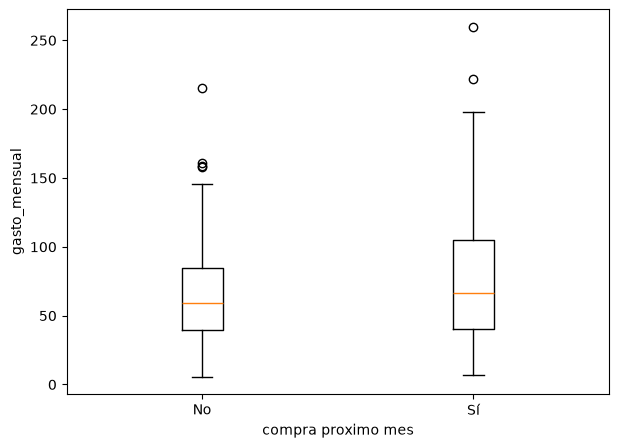

In [37]:
# TODO: crea grupo_no y grupo_si
#loc permirte filtrar usando condiciones entonces si yo le digo coge el dataframe accede a compra proimo mes == no esta creando una condicion esa condicion es que que la columna el campo compra proximo mes sea no
#df['compra_proximo_mes']=='No'

#si eso yo le paso l loc es el filtrado de las filas quedarte con las que tengan valor no en la comlumna proximo mes
grupo_no = df.loc[df['compra_proximo_mes']=='No', "gasto_mensual"].dropna() #quito nan
#filtro por fila con valor no en columna compra proxima mes saca el gasto mensual de los clientes que no van a comprar el  proximo mes


grupo_si = df.loc[df['compra_proximo_mes']=='Sí', "gasto_mensual"].dropna()

plt.figure(figsize=(7,5))
plt.boxplot([grupo_no, grupo_si], tick_labels=['No', 'Sí'])
plt.xlabel("compra proximo mes")
plt.ylabel("gasto_mensual")
plt.show()


# TODO: representa ambos grupos mediante un boxplot

### Interpreta

1. ¿Qué grupo presenta una mediana mayor?
2. ¿Cuál parece tener mayor dispersión?
3. ¿Existen outliers en ambos?
4. ¿El gráfico apoya las conclusiones obtenidas mediante `groupby()`?

**Respuesta:**  
1\. Los que compran  
2\. Los que compran  
3\. Si, en los dos  
4\. Si, los que compran gastan un poco mas

# Parte 15 - Dos variables categóricas

Queremos responder:

> **¿La proporción de compra es igual para todos los niveles de fidelidad?**

## Ejercicio 15

Crea:

1. una tabla de contingencia con frecuencias absolutas
2. una tabla normalizada por filas mediante `normalize="index"`
3. una versión expresada en porcentajes.

In [38]:
# TODO: tabla de contingencia con frecuencias absolutas

frecuencias = pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'])
frecuencias

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,112,50
Oro,52,31
Plata,63,42
Platino,19,31


In [39]:
# TODO: tabla normalizada por filas normalizar es que te saca el porcentaje
frecuencias = pd.crosstab(df['nivel_fidelidad'], df['compra_proximo_mes'], normalize="index")
frecuencias


compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,0.691358,0.308642
Oro,0.626506,0.373494
Plata,0.600000,0.400000
Platino,0.380000,0.620000


In [40]:
# TODO: muestra las proporciones como porcentajes
(frecuencias * 100).round(2)

compra_proximo_mes,No,Sí
nivel_fidelidad,,
Bronce,69.14,30.86
Oro,62.65,37.35
Plata,60.00,40.00
Platino,38.00,62.00


### Interpreta

1. ¿Qué nivel tiene mayor número absoluto de clientes que compran?
2. ¿Qué nivel tiene mayor porcentaje de clientes que compran?
3. ¿Coinciden necesariamente ambas respuestas?
4. ¿Por qué son importantes las proporciones cuando los grupos tienen tamaños diferentes?

**Respuesta:**  
1\. Bronce (50)  
2\. Platino (62 %)  
3\. No  
4\. Porque si un grupo es mas grande tiene mas compradores aunque su porcentaje sea menor

# Parte 16 - Correlación no implica causalidad

## Ejercicio 16 - Razonamiento

Un compañero observa una relación entre `nivel_fidelidad` y `compra_proximo_mes` y afirma:

> **«Subir a un cliente al nivel Platino hará que compre el próximo mes».**

¿Es correcta esta conclusión?

Redacta entre **5 y 8 líneas** utilizando correctamente:

- asociación
- causalidad
- variables adicionales
- evidencia

### Respuesta

No es correcta. Hay una asociacion entre el nivel y la compra, Platino compra un 62 % y Bronce un 31 %, pero eso no es causalidad.  
Puede ser al reves, los que compran mucho llegan a Platino, o que influyan otras variables como el gasto o la antiguedad  
Para tener evidencia habria que hacer un experimento, subir de nivel a unos clientes al azar y compararlos con otros

# Parte 17 - Investiga una hipótesis

## Ejercicio 17

Elige **una**:

**A.** ¿Los clientes con mayores ingresos gastan más mensualmente?  
**B.** ¿Los clientes más antiguos realizan más compras?  
**C.** ¿La satisfacción está relacionada con el número de compras?  
**D.** ¿El número de devoluciones está relacionado con la satisfacción?

Realiza:

1. selección de variables
2. estadística descriptiva
3. visualización adecuada
4. correlación si procede
5. interpretación.

Clientes con ambos valores: 395


,count,mean,std,min,25%,50%,75%,max
antiguedad_meses,395.0,59.85,34.11,1.0,31.0,59.0,90.0,120.0
num_compras,395.0,8.20,2.78,2.0,6.0,8.0,10.0,17.0


,count,mean,median,std
tramo_antiguedad,,,,
Q1 (más nuevos),101,8.47,8.0,2.97
Q2,99,8.29,8.0,2.48
Q3,98,8.43,8.0,2.67
Q4 (más antiguos),97,7.61,7.0,2.91


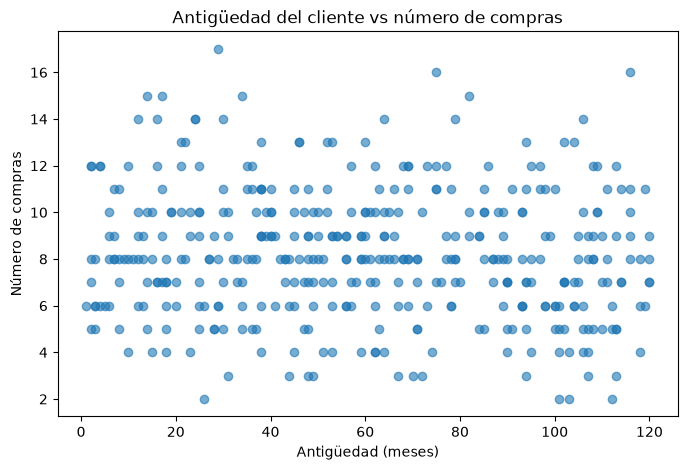

Correlación de Pearson antigüedad - nº compras: r = -0.100


In [41]:
# TODO: desarrolla aquí el análisis de la hipótesis seleccionada
# Hipótesis B: ¿Los clientes más antiguos realizan más compras?
# 1. Selección de variables
hip = df[["antiguedad_meses", "num_compras"]].dropna()
print("Clientes con ambos valores:", len(hip))

# 2. Estadística descriptiva
display(hip.describe().T.round(2))

# Comparación por tramos de antigüedad (cuartiles)
hip["tramo_antiguedad"] = pd.qcut(hip["antiguedad_meses"], q=4,
                                  labels=["Q1 (más nuevos)", "Q2", "Q3", "Q4 (más antiguos)"])
display(hip.groupby("tramo_antiguedad", observed=True)["num_compras"]
           .agg(["count", "mean", "median", "std"]).round(2))

# 3. Visualización
plt.figure(figsize=(8,5))
plt.scatter(hip["antiguedad_meses"], hip["num_compras"], alpha=0.6)
plt.title("Antigüedad del cliente vs número de compras")
plt.xlabel("Antigüedad (meses)")
plt.ylabel("Número de compras")
plt.show()

# 4. Correlación
r_hip = hip["antiguedad_meses"].corr(hip["num_compras"])
print(f"Correlación de Pearson antigüedad - nº compras: r = {r_hip:.3f}")

### Conclusión de la hipótesis

Redacta entre **5 y 10 líneas**. No escribas únicamente el valor de correlación.

**Respuesta:**  
He elegido la B: ¿los clientes mas antiguos realizan mas compras?  
La correlacion es -0,10, muy debil  
En el scatter no se ve ninguna tendencia  
Por tramos de antiguedad todos hacen unas 8 compras, los mas antiguos un poco menos (7,6)  
Asi que no, ser mas antiguo no hace que compres mas  
La diferencia es pequeña y no demuestra causalidad

# Parte 18 - El reto del analista

## Ejercicio 18

Trabaja ahora con mayor autonomía:

> **¿Qué características parecen diferenciar a los clientes que compran el mes siguiente de los que no compran?**

Puedes investigar:

`edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad` y `satisfaccion`.

Tu análisis debe contener como mínimo:

- una comparación numérica
- una comparación categórica
- dos visualizaciones
- estadísticas descriptivas
- una tabla de proporciones.

In [42]:
# TODO: comparación numérica
# Estadísticas descriptivas de las variables numéricas por grupo
vars_num = ["edad", "antiguedad_meses", "ingresos_anuales", "gasto_mensual",
            "num_compras", "devoluciones", "satisfaccion"]
print("Medias por grupo:")
display(df.groupby("compra_proximo_mes")[vars_num].mean().round(2).T)
print("Medianas por grupo:")
display(df.groupby("compra_proximo_mes")[vars_num].median().round(2).T)

Medias por grupo:


compra_proximo_mes,No,Sí
edad,47.81,44.15
antiguedad_meses,59.47,60.46
ingresos_anuales,36457.79,36413.55
gasto_mensual,64.59,76.34
num_compras,8.15,8.35
devoluciones,1.29,1.12
satisfaccion,3.28,3.40


Medianas por grupo:


compra_proximo_mes,No,Sí
edad,47.50,44.00
antiguedad_meses,59.00,60.50
ingresos_anuales,36999.62,36715.09
gasto_mensual,59.28,66.50
num_compras,8.00,8.00
devoluciones,1.00,1.00
satisfaccion,3.00,3.00


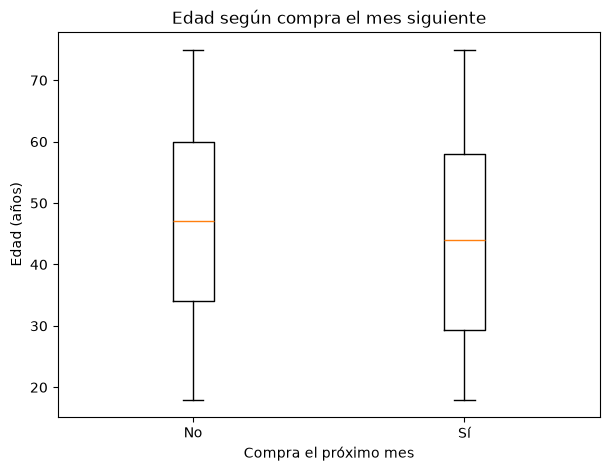

In [43]:
# TODO: primera visualización
# Edad según compra el mes siguiente (sin la edad imposible de 195 años)
edad_valida = df[df["edad"] <= 120]
plt.figure(figsize=(7,5))
plt.boxplot([edad_valida.loc[edad_valida["compra_proximo_mes"] == "No", "edad"],
             edad_valida.loc[edad_valida["compra_proximo_mes"] == "Sí", "edad"]],
            tick_labels=["No", "Sí"])
plt.title("Edad según compra el mes siguiente")
plt.xlabel("Compra el próximo mes")
plt.ylabel("Edad (años)")
plt.show()

In [44]:
# TODO: comparación categórica y tabla de proporciones
# Porcentaje de clientes que compran según cada variable categórica
for col in ["nivel_fidelidad", "dispositivo", "zona"]:
    tabla = (pd.crosstab(df[col], df["compra_proximo_mes"], normalize="index") * 100).round(2)
    tabla["n_clientes"] = df[col].value_counts()
    display(tabla.sort_values("Sí", ascending=False))

compra_proximo_mes,No,Sí,n_clientes
nivel_fidelidad,,,
Platino,38.00,62.00,50
Plata,60.00,40.00,105
Oro,62.65,37.35,83
Bronce,69.14,30.86,162


compra_proximo_mes,No,Sí,n_clientes
dispositivo,,,
Ordenador,57.89,42.11,133
Móvil,63.22,36.78,242
Tablet,64.00,36.00,25


compra_proximo_mes,No,Sí,n_clientes
zona,,,
Norte,54.43,45.57,79
Oeste,57.89,42.11,76
Centro,63.16,36.84,76
Este,64.04,35.96,89
Sur,67.50,32.50,80


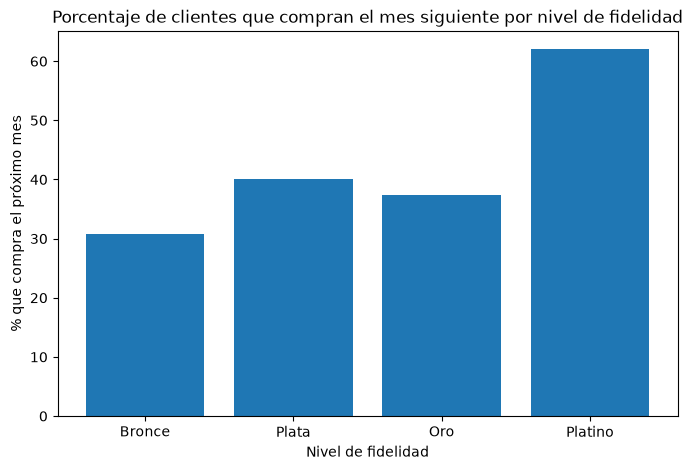

In [45]:
# TODO: segunda visualización
# Porcentaje de compra por nivel de fidelidad (en orden)
orden = ["Bronce", "Plata", "Oro", "Platino"]
pct_compra = (pd.crosstab(df["nivel_fidelidad"], df["compra_proximo_mes"],
                          normalize="index")["Sí"] * 100).reindex(orden)
plt.figure(figsize=(8,5))
plt.bar(pct_compra.index, pct_compra.values)
plt.title("Porcentaje de clientes que compran el mes siguiente por nivel de fidelidad")
plt.xlabel("Nivel de fidelidad")
plt.ylabel("% que compra el próximo mes")
plt.show()

### Interpretación del reto

Resume qué características parecen diferenciar a ambos grupos.

Distingue entre:

- lo que **observas** en el dataset
- lo que **no puedes concluir** a partir de esos datos.

**Respuesta:**  
Lo que se observa:  
El nivel de fidelidad es lo que mas cambia, Platino compra un 62 % y Bronce un 31 %  
Los que compran gastan algo mas y son algo mas jovenes  
Por zona y dispositivo hay algo de diferencia pero poca  
Ingresos, antiguedad, compras, devoluciones y satisfaccion son casi iguales en los dos grupos  
  
Lo que no se puede concluir:  
Que estas variables causen la compra  
Que las diferencias pequeñas no sean por casualidad

# Parte 19 - Informe final de EDA

## Ejercicio 19

Selecciona los **5 hallazgos más relevantes**.

Para cada uno indica:

- **Pregunta:** ¿qué queríamos averiguar?
- **Evidencia:** ¿qué estadística, tabla o gráfico lo respalda?
- **Interpretación:** ¿qué hemos observado?
- **Limitación:** ¿qué no podemos concluir?

### Hallazgo 1
**Pregunta:** ¿Como es el gasto mensual?  
**Evidencia:** describe(), histograma y boxplot  
**Interpretación:** La mayoria gasta entre 40 y 90 € y algunos mucho mas (hasta 260 €)  
**Limitación:** No sabemos si los gastos altos son reales

### Hallazgo 2
**Pregunta:** ¿Hay datos erroneos?  
**Evidencia:** describe() de edad y isna()  
**Interpretación:** Hay una edad de 195 años y 12 ausentes  
**Limitación:** No sabemos cual es la edad correcta

### Hallazgo 3
**Pregunta:** ¿Estan equilibradas las clases?  
**Evidencia:** value_counts() y grafico de barras  
**Interpretación:** 61,5 % No y 38,5 % Si  
**Limitación:** No sabemos si pasa igual en otros meses

### Hallazgo 4
**Pregunta:** ¿Se relacionan las variables numericas?  
**Evidencia:** Matriz de correlaciones y scatter  
**Interpretación:** Todas las correlaciones son muy debiles  
**Limitación:** Solo mide relaciones lineales

### Hallazgo 5
**Pregunta:** ¿Que diferencia a los que compran?  
**Evidencia:** crosstab de nivel_fidelidad y groupby del gasto  
**Interpretación:** Platino compra un 62 % y Bronce un 31 %, y los que compran gastan algo mas  
**Limitación:** Es asociacion, no causalidad

# Parte 20 - Conclusiones

## Ejercicio 20

Redacta unas conclusiones finales de entre **10 y 15 líneas**.

Incluye:

- características generales del dataset
- principales distribuciones
- posibles valores atípicos
- relaciones encontradas
- correlaciones relevantes
- diferencias entre grupos
- algún resultado que te haya sorprendido
- posibles problemas de calidad
- qué investigarías a continuación.

### Conclusiones

El dataset tiene 400 clientes y 12 columnas, el target es compra_proximo_mes con 61,5 % No y 38,5 % Si  
Hay pocos ausentes, 12 en total  
El gasto mensual tiene cola a la derecha, con 9 outliers por encima de 165 €, que no he eliminado  
Ingresos y numero de compras son bastante simetricos  
Hay una edad de 195 años que es un error, y 16 clientes con ingresos de 9.000 € justos que habria que revisar  
Las correlaciones entre variables numericas son todas muy debiles  
Me ha sorprendido que los ingresos no tengan relacion con el gasto  
La mayor diferencia entre grupos esta en el nivel de fidelidad, Platino compra mucho mas  
Los que compran gastan algo mas y son algo mas jovenes  
Todo esto son asociaciones, no causas  
Como siguiente paso arreglaria los datos raros y probaria un modelo de clasificacion

# Antes de entregar

Comprueba que:

- [ ] Has completado todos los ejercicios.
- [ ] Has respondido las preguntas en Markdown.
- [ ] Todos los gráficos tienen título.
- [ ] Los ejes están correctamente identificados.
- [ ] Has interpretado los resultados.
- [ ] Has diferenciado correlación de causalidad.
- [ ] No has eliminado automáticamente los outliers.
- [ ] Has ejecutado el notebook completo desde el principio sin errores.

**Nombre recomendado:** `Practica_05_Apellido_Nombre.ipynb`